# IND320 Assignment 2

## GitHub and Streamlit app
GitHub repository can be found [Here](https://github.com/ptilrem/ptilrem-D2D-SLapp/tree/main)

Streamlit app can be found [Here](https://ptilrem-d2d-slapp.streamlit.app/)

## Tasks

### Imports

In [ ]:
# Standard Python libraries
import os
import sys
from xml.etree import ElementTree as ET


# Data retrieval and processing
import requests
import pandas as pd
from dotenv import load_dotenv

# Visualization
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Spark and Cassandra
import pyspark
from pyspark.sql import SparkSession, functions as F, types as T
from cassandra.cluster import Cluster

# MongoDB
from pymongo import MongoClient, ReplaceOne

### Preparation

In [ ]:
# Load API and database credentials from the local .env file.
load_dotenv(override=True)

ENTSOE_TOKEN = os.getenv("ENTSOE_TOKEN", "").strip()
MONGODB_URI = os.getenv("MONGODB_URI", "").strip()

# Configure Java, Hadoop and Python for local Spark execution.
# Environment variables must be configured before Spark starts.
os.environ["JAVA_HOME"] = r"C:\Program Files\Microsoft\jdk-17.0.20.101-hotspot"
os.environ["HADOOP_HOME"] = r"C:\Hadoop\hadoop-3.3.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Verify the Python environment and availability of credentials.
print("Python:", sys.version.split()[0])
print("ENTSO-E token configured:", bool(ENTSOE_TOKEN))
print("MongoDB URI configured:", bool(MONGODB_URI))

Python: 3.12.10
ENTSO-E token configured: True
MongoDB URI configured: True


### Spark-Cassandra setup

In [ ]:
# Initialize Spark with the Cassandra connector.
spark = (
    SparkSession.builder
    .appName("IND320_Assignment2")
    .master("local[2]")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)

# Reduce unnecessary console messages.
spark.sparkContext.setLogLevel("WARN")

# Verify the Spark installation and Cassandra connector.
print("PySpark version:", pyspark.__version__)
print("Spark version:", spark.version)
print("Cassandra connector:",
      spark.sparkContext.getConf().get("spark.jars.packages"))

PySpark version: 3.5.9
Spark version: 3.5.1
Cassandra connector: com.datastax.spark:spark-cassandra-connector_2.12:3.5.1


In [4]:
# Connect to the local Cassandra database.
cluster = Cluster(["127.0.0.1"], port=9042)
cas = cluster.connect()

# Create a keyspace for Assignment 2.
cas.execute("""
CREATE KEYSPACE IF NOT EXISTS ind320_a2
WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}
""")

# Create a table for the ENTSO-E electricity-transfer observations.
cas.execute("""
CREATE TABLE IF NOT EXISTS ind320_a2.entsoe_flows_utc (
    connection text,
    direction text,
    date_utc text,
    timestamp_utc timestamp,
    power_mw double,
    duration_hours double,
    energy_mwh double,
    PRIMARY KEY ((connection, direction, date_utc), timestamp_utc)
)
""")

print("Cassandra table ready: ind320_a2.entsoe_flows_utc")

Cassandra table ready: ind320_a2.entsoe_flows_utc


In [5]:
# Verify that Spark can read the ENTSO-E data from Cassandra.
connection_check = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(table="entsoe_flows_utc", keyspace="ind320_a2")
    .load()
)

connection_check.select(
    "connection", "direction", "date_utc", "energy_mwh"
).limit(3).show(truncate=False)

print("Spark-Cassandra connection successful.")

+----------+-----------+----------+----------+
|connection|direction  |date_utc  |energy_mwh|
+----------+-----------+----------+----------+
|NO4-SE2   |Into Norway|2025-01-15|36.8425   |
|NO4-SE2   |Into Norway|2025-01-15|3.8925    |
|NO4-SE2   |Into Norway|2025-01-15|0.0       |
+----------+-----------+----------+----------+

Spark-Cassandra connection successful.


### MongoDB

In [6]:
# Connect to MongoDB Atlas using credentials from the .env file.
client = MongoClient(MONGODB_URI, serverSelectionTimeoutMS=10000)
client.admin.command("ping")

# Create a separate collection for testing database operations.
test_collection = client["ind320_assignment2"]["connection_test"]

# Insert a test document (or replace it if already present).
test_collection.replace_one(
    {"_id": "test"},
    {"_id": "test", "status": "created"},
    upsert=True
)

# Read the document from MongoDB.
print("Read:", test_collection.find_one({"_id": "test"}))

# Update the document and verify the change.
test_collection.update_one(
    {"_id": "test"},
    {"$set": {"status": "updated"}}
)
print("Updated:", test_collection.find_one({"_id": "test"}))

# Delete the test document.
test_collection.delete_one({"_id": "test"})

print("MongoDB connection and operations successful!")

Read: {'_id': 'test', 'status': 'created'}
Updated: {'_id': 'test', 'status': 'updated'}
MongoDB connection and operations successful!


### NVE API

In [7]:
# Download reservoir statistics and geographical area information from NVE.
NVE_BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

def get_nve(endpoint):
    response = requests.get(f"{NVE_BASE}/{endpoint}", timeout=90)
    response.raise_for_status()
    return response.json()

nve_records = get_nve("HentOffentligData")
nve_areas = get_nve("HentOmråder")

print("Reservoir data response:", type(nve_records).__name__)
print("Area data response:", type(nve_areas).__name__)
print("Number of reservoir records:", len(nve_records))

Reservoir data response: list
Area data response: list
Number of reservoir records: 14931


In [8]:
# Convert the API response into a Pandas DataFrame.
nve_df = pd.DataFrame(nve_records)

# Convert the date column into Pandas datetime format.
nve_df["dato_Id"] = pd.to_datetime(nve_df["dato_Id"])

# Display information about the retrieved dataset.
print("Area types:", nve_df["omrType"].value_counts().to_dict())
print("Date range:", nve_df["dato_Id"].min(), "to", nve_df["dato_Id"].max())
print("Total observations:", len(nve_df))

display(nve_df.head())

Area types: {'EL': 8295, 'VASS': 4977, 'NO': 1659}
Date range: 1995-01-08 00:00:00 to 2026-10-18 00:00:00
Total observations: 14931


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [9]:
# Combine the geographical area categories into one DataFrame.
nve_area_df = pd.concat(
    [pd.DataFrame(nve_areas[0][category])
     for category in ["land", "elspot", "vassdrag"]],
    ignore_index=True
)

display(nve_area_df)

,navn,navn_langt,beskrivelse,omrType,omrnr
0,Norge,Norge,Hele landet,NO,0
1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1
2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2
3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3
4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4
5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5
6,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1
7,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2
8,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3
9,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4


In [10]:
# Rename the Norwegian columns to English, as in Assignment 1.
column_rename_dict = {
    "dato_Id": "date_id",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "fill_percentage",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publish_date",
    "fyllingsgrad_forrige_uke": "fill_percentage_last_week",
    "endring_fyllingsgrad": "change_fill_percentage"
}

# Measurements used in the reservoir visualizations.
measurement_columns = [
    "fill_percentage",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_percentage_last_week",
    "change_fill_percentage"
]

# Apply the English column names and sort chronologically by area.
reservoir_df = (
    nve_df.rename(columns=column_rename_dict)
    .sort_values(["date_id", "area_type", "area_number"])
    .reset_index(drop=True)
)

print("Total observations:", len(reservoir_df))
print("Date range:", reservoir_df["date_id"].min(),
      "to", reservoir_df["date_id"].max())

display(reservoir_df.head())

Total observations: 14931
Date range: 1995-01-08 00:00:00 to 2026-10-18 00:00:00


,date_id,area_type,area_number,iso_year,iso_week,fill_percentage,capacity_TWh,stored_energy_TWh,next_publish_date,fill_percentage_last_week,change_fill_percentage
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
1,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657
2,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349
3,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,0001-01-01T00:00:00,0.801348,-0.242484
4,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160


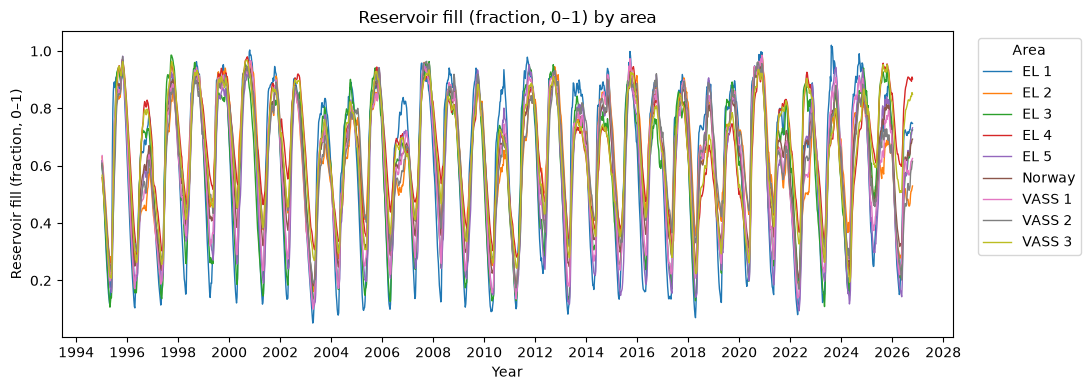

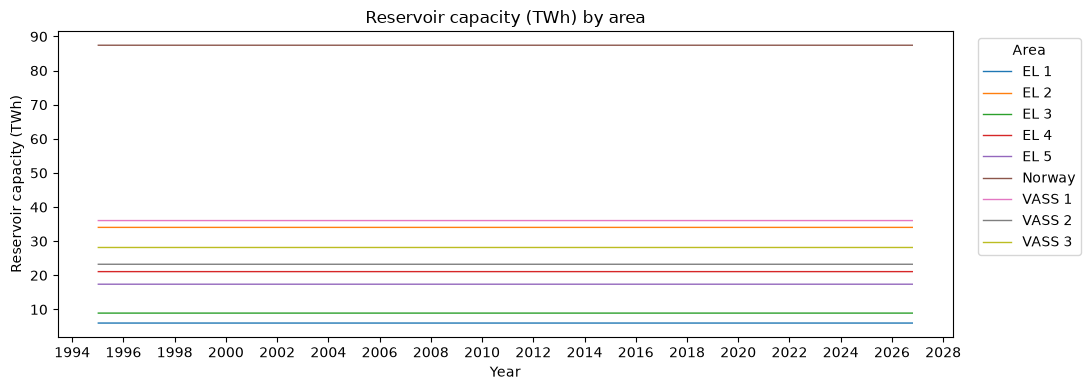

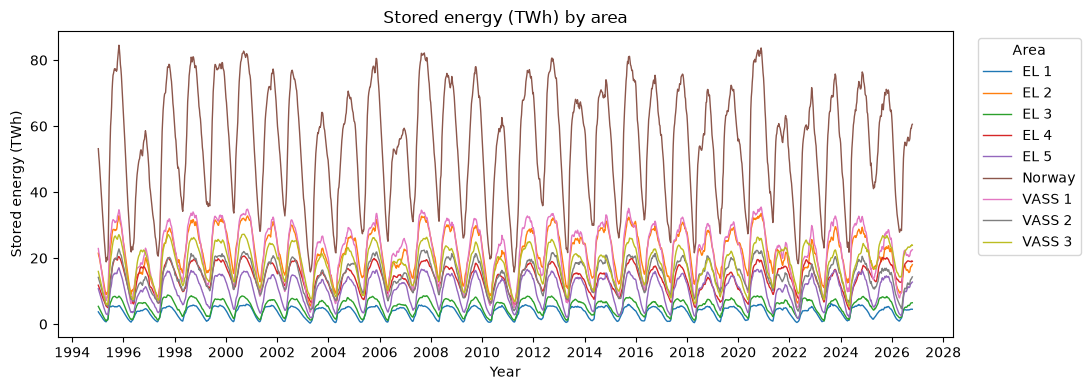

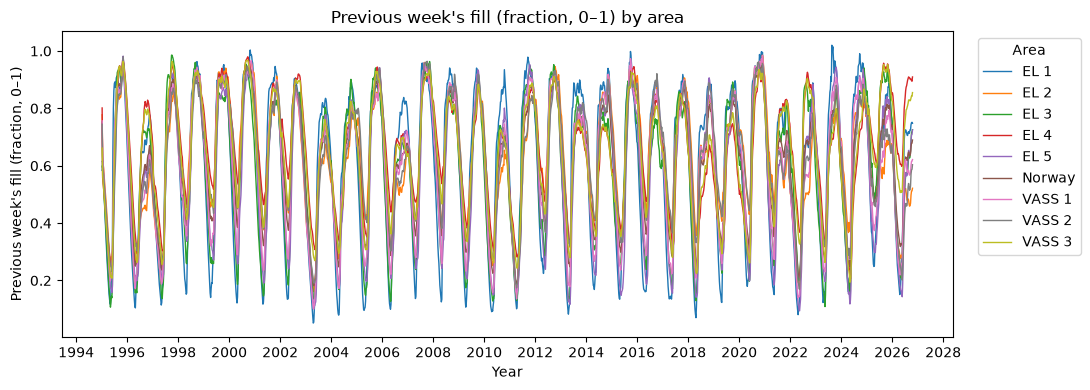

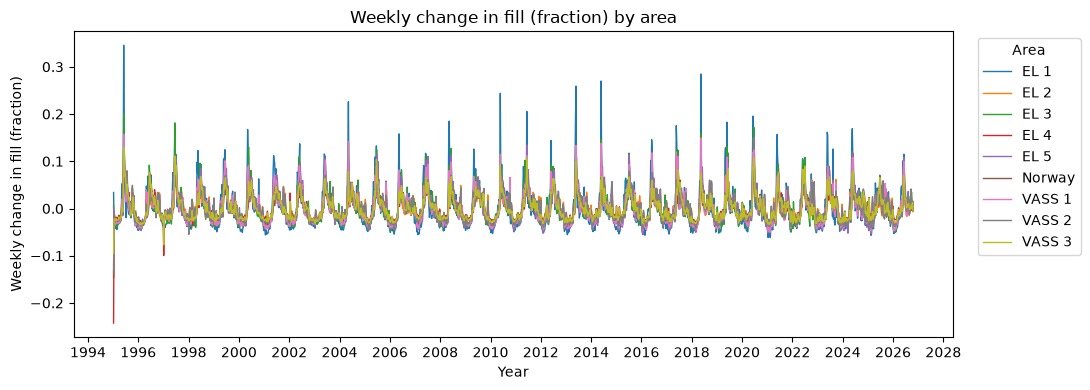

In [11]:
# Define readable labels and units for the five measurements.
measurement_labels = {
    "fill_percentage": "Reservoir fill (fraction, 0–1)",
    "capacity_TWh": "Reservoir capacity (TWh)",
    "stored_energy_TWh": "Stored energy (TWh)",
    "fill_percentage_last_week": "Previous week's fill (fraction, 0–1)",
    "change_fill_percentage": "Weekly change in fill (fraction)"
}

# Create one plot for each measurement.
for col in measurement_columns:
    fig, ax = plt.subplots(figsize=(11, 4))

    # Plot each geographical area as a separate line.
    for (area_type, area_number), group in reservoir_df.groupby(
        ["area_type", "area_number"]
    ):
        label = "Norway" if area_type == "NO" else f"{area_type} {area_number}"

        ax.plot(
            group["date_id"],
            group[col],
            label=label,
            linewidth=1
        )

    # Format the graph and its axes.
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    ax.set_title(f"{measurement_labels[col]} by area")
    ax.set_xlabel("Year")
    ax.set_ylabel(measurement_labels[col])
    ax.legend(title="Area", bbox_to_anchor=(1.02, 1), loc="upper left")

    plt.tight_layout()
    plt.show()

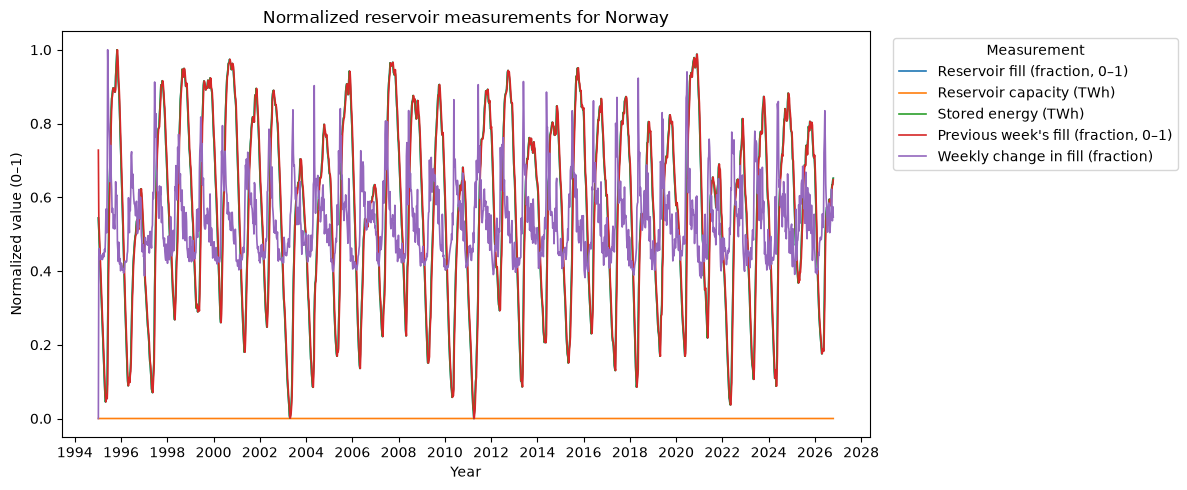

In [12]:
# Select nationwide reservoir measurements for the combined plot.
norway_df = reservoir_df[reservoir_df["area_type"] == "NO"].sort_values("date_id")

fig, ax = plt.subplots(figsize=(12, 5))

# Normalize each measurement independently to the range 0–1.
for col in measurement_columns:
    values = norway_df[col]
    value_range = values.max() - values.min()

    if value_range == 0:
        scaled_values = values * 0
    else:
        scaled_values = (values - values.min()) / value_range

    ax.plot(
        norway_df["date_id"],
        scaled_values,
        label=measurement_labels[col],
        linewidth=1.2
    )

# Format the combined plot.
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.set_title("Normalized reservoir measurements for Norway")
ax.set_xlabel("Year")
ax.set_ylabel("Normalized value (0–1)")
ax.legend(title="Measurement", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### ENTSO-E API

In [13]:
# Convert ENTSO-E XML into electricity-transfer records.
def parse_entsoe_xml(xml_data, connection, direction):
    root = ET.fromstring(xml_data)
    records = []

    for series in root.findall(".//{*}TimeSeries"):
        for period in series.findall("{*}Period"):

            # Read the measurement period and resolution.
            start = pd.Timestamp(period.findtext("{*}timeInterval/{*}start"))
            end = pd.Timestamp(period.findtext("{*}timeInterval/{*}end"))
            step = pd.Timedelta(period.findtext("{*}resolution"))

            # Sort points by their position within the period.
            points = sorted(
                period.findall("{*}Point"),
                key=lambda p: int(p.findtext("{*}position"))
            )

            for i, point in enumerate(points):
                position = int(point.findtext("{*}position"))
                quantity = point.findtext("{*}quantity")
                block_start = start + (position - 1) * step

                # Each block ends at the next point, or at the period end.
                if i + 1 < len(points):
                    next_position = int(points[i + 1].findtext("{*}position"))
                    block_end = start + (next_position - 1) * step
                else:
                    block_end = end

                if quantity is None:
                    continue

                power = float(quantity)

                # Split blocks at midnight for accurate daily totals.
                while block_start < block_end:
                    midnight = block_start.normalize() + pd.Timedelta(days=1)
                    segment_end = min(block_end, midnight)
                    hours = (segment_end - block_start).total_seconds() / 3600

                    records.append({
                        "connection": connection,
                        "direction": direction,
                        "date_utc": block_start.strftime("%Y-%m-%d"),
                        "timestamp_utc": block_start.to_pydatetime(),
                        "power_mw": power,
                        "duration_hours": hours,
                        "energy_mwh": power * hours
                    })

                    block_start = segment_end

    return records

In [14]:
# ENTSO-E area codes for Norway and its international neighbours.
EIC = {
    "NO_1": "10YNO-1--------2",
    "NO_2": "10YNO-2--------T",
    "NO_3": "10YNO-3--------J",
    "NO_4": "10YNO-4--------9",
    "SE_1": "10Y1001A1001A44P",
    "SE_2": "10Y1001A1001A45N",
    "SE_3": "10Y1001A1001A46L",
    "DK_1": "10YDK-1--------W",
    "NL": "10YNL----------L",
    "DE_LU": "10Y1001A1001A82H",
    "GB": "10YGB----------A",
    "FI": "10YFI-1--------U"
}

# International connections between Norwegian and foreign bidding zones.
CONNECTIONS = [
    ("NO1-SE3", "NO_1", "SE_3"),
    ("NO2-DK1", "NO_2", "DK_1"),
    ("NO2-NL", "NO_2", "NL"),
    ("NO2-DE-LU", "NO_2", "DE_LU"),
    ("NO2-GB", "NO_2", "GB"),
    ("NO3-SE2", "NO_3", "SE_2"),
    ("NO4-SE1", "NO_4", "SE_1"),
    ("NO4-SE2", "NO_4", "SE_2"),
    ("NO4-FI", "NO_4", "FI")
]

# Retrieve the last two complete years, excluding the current day.
# END_UTC = pd.Timestamp.now(tz="UTC").normalize()
# START_UTC = END_UTC - pd.DateOffset(years=2)

# Date range of the ENTSO-E dataset stored in Cassandra.
START_UTC = pd.Timestamp("2024-10-27", tz="UTC")
END_UTC = pd.Timestamp("2026-10-27", tz="UTC")

# ENTSO-E API endpoint and database destinations.
ENTSOE_URL = "https://web-api.tp.entsoe.eu/api"
raw_table = "entsoe_flows_utc"
mongo_collection = "entsoe_daily_flows"

print("Period:", START_UTC.date(), "to", END_UTC.date(), "(exclusive)")
print("Connections:", len(CONNECTIONS))
print("Directions:", len(CONNECTIONS) * 2)
print("Borders:", [name for name, _, _ in CONNECTIONS])

Period: 2024-10-27 to 2026-10-27 (exclusive)
Connections: 9
Directions: 18
Borders: ['NO1-SE3', 'NO2-DK1', 'NO2-NL', 'NO2-DE-LU', 'NO2-GB', 'NO3-SE2', 'NO4-SE1', 'NO4-SE2', 'NO4-FI']


In [15]:
# Retrieve cross-border electricity flows from the ENTSO-E API.
def fetch_entsoe_flows(connection, out_area, in_area, direction, start, end):
    params = {
        "securityToken": ENTSOE_TOKEN,
        "documentType": "A11",
        "out_Domain": EIC[out_area],
        "in_Domain": EIC[in_area],
        "periodStart": start.strftime("%Y%m%d%H%M"),
        "periodEnd": end.strftime("%Y%m%d%H%M")
    }

    response = requests.get(ENTSOE_URL, params=params, timeout=90)
    response.raise_for_status()

    # Check whether ENTSO-E returned measurements or an error message.
    root = ET.fromstring(response.content)

    if root.tag.endswith("Acknowledgement_MarketDocument"):
        message = root.findtext(".//{*}Reason/{*}text")
        raise ValueError(f"{connection} ({direction}): {message}")

    return parse_entsoe_xml(response.content, connection, direction)

In [16]:
# Split the two-year period into monthly API request windows.
def monthly_windows(start, end):
    month_starts = pd.date_range(start=start, end=end, freq="MS")
    boundaries = [start] + [
        date for date in month_starts if start < date < end
    ] + [end]

    return list(zip(boundaries[:-1], boundaries[1:]))


windows = monthly_windows(START_UTC, END_UTC)

print("Monthly windows:", len(windows))
print("First window:", windows[0])
print("Last window:", windows[-1])
print("Total API requests needed:", len(windows) * len(CONNECTIONS) * 2)

Monthly windows: 25
First window: (Timestamp('2024-10-27 00:00:00+0000', tz='UTC'), Timestamp('2024-11-01 00:00:00+0000', tz='UTC'))
Last window: (Timestamp('2026-10-01 00:00:00+0000', tz='UTC'), Timestamp('2026-10-27 00:00:00+0000', tz='UTC'))
Total API requests needed: 450


In [17]:
# Download one time window for every international connection.
def download_entsoe_window(start, end):
    all_records = []
    results = []
    expected_hours = (end - start).total_seconds() / 3600

    for connection, norway_area, foreign_area in CONNECTIONS:
        directions = [
            ("Out of Norway", norway_area, foreign_area),
            ("Into Norway", foreign_area, norway_area)
        ]

        for direction, out_area, in_area in directions:
            try:
                records = fetch_entsoe_flows(
                    connection, out_area, in_area, direction, start, end
                )

                hours = sum(row["duration_hours"] for row in records)
                complete = abs(hours - expected_hours) < 0.01
                status = "OK" if complete else "Incomplete"

                if complete:
                    all_records.extend(records)

            except requests.HTTPError as error:
                hours = 0
                status = f"HTTP {error.response.status_code}"

            except (requests.RequestException, ValueError, ET.ParseError) as error:
                hours = 0
                status = type(error).__name__

            results.append({
                "connection": connection,
                "direction": direction,
                "hours": hours,
                "status": status
            })

            print(f"{connection} — {direction}: {status}")

    return all_records, pd.DataFrame(results)

### Insert data into Cassandra using Spark

In [18]:
# Define the Spark schema to match the existing Cassandra table.
FLOW_SCHEMA = T.StructType([
    T.StructField("connection", T.StringType()),
    T.StructField("direction", T.StringType()),
    T.StructField("date_utc", T.StringType()),
    T.StructField("timestamp_utc", T.TimestampType()),
    T.StructField("power_mw", T.DoubleType()),
    T.StructField("duration_hours", T.DoubleType()),
    T.StructField("energy_mwh", T.DoubleType())
])

# Write ENTSO-E records to Cassandra through Spark.
def write_to_cassandra(records):
    if records:
        df = spark.createDataFrame(records, schema=FLOW_SCHEMA)

        (df.write.format("org.apache.spark.sql.cassandra")
         .options(table=raw_table, keyspace="ind320_a2")
         .mode("append")
         .save())

In [19]:
# Set to True only when new ENTSO-E data needs to be downloaded.
RUN_ENTSOE_DOWNLOAD = False

if RUN_ENTSOE_DOWNLOAD:
    for start, end in windows:
        records, report = download_entsoe_window(start, end)

        # Stop if any connection has incomplete measurements.
        if not (report["status"] == "OK").all():
            display(report[report["status"] != "OK"])
            raise RuntimeError(f"Incomplete data for {start.date()}")

        # Save the measurements to Cassandra using Spark.
        write_to_cassandra(records)

        print(f"Saved {start.date()} to {end.date()}: {len(records)} records")

else:
    print(f"Download skipped. Using existing Cassandra table: {raw_table}")

Download skipped. Using existing Cassandra table: entsoe_flows_utc


In [20]:
# Read the existing ENTSO-E measurements from Cassandra.
corrected_flows = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(table=raw_table, keyspace="ind320_a2")
    .load()
)

# Verify that the table contains electricity measurements.
stored_rows = corrected_flows.count()

print("Records in Cassandra:", stored_rows)

if stored_rows == 0:
    raise RuntimeError("The ENTSO-E Cassandra table is empty.")

Records in Cassandra: 492913


In [21]:
# Verify that each connection and direction has 24 hours of data per day.
daily_coverage = (
    corrected_flows
    .groupBy("connection", "direction", "date_utc")
    .agg(F.sum("duration_hours").alias("hours"))
)

# Check the expected number of connection-days.
expected_days = (END_UTC - START_UTC).days
expected_groups = expected_days * len(CONNECTIONS) * 2

incomplete_days = daily_coverage.filter(
    F.abs(F.col("hours") - 24) > 0.01
)

print("Expected connection-days:", expected_groups)
print("Stored connection-days:", daily_coverage.count())
print("Incomplete days:", incomplete_days.count())

Expected connection-days: 13140
Stored connection-days: 13140
Incomplete days: 0


### Extracting relevant columns from Cassandra with Spark

In [22]:
# Extract the columns needed for electricity transfer analysis.
flow_data = corrected_flows.select(
    "connection",
    "direction",
    "date_utc",
    "energy_mwh"
)

# Calculate daily electricity transfers for each connection and direction.
daily_flows_spark = (
    flow_data
    .groupBy("connection", "direction", "date_utc")
    .agg(F.sum("energy_mwh").alias("energy_mwh"))
    .orderBy("date_utc", "connection", "direction")
)

# Convert the aggregated results to Pandas for visualization.
daily_flows_df = daily_flows_spark.toPandas()
daily_flows_df["date_utc"] = pd.to_datetime(daily_flows_df["date_utc"])

print("Daily observations:", len(daily_flows_df))
print("Connections:", daily_flows_df["connection"].nunique())
print("Directions:", daily_flows_df["direction"].nunique())

display(daily_flows_df.head())

Daily observations: 13140
Connections: 9
Directions: 2


,connection,direction,date_utc,energy_mwh
0,NO1-SE3,Into Norway,2024-10-27,44152.755
1,NO1-SE3,Out of Norway,2024-10-27,0.000
2,NO2-DE-LU,Into Norway,2024-10-27,0.000
3,NO2-DE-LU,Out of Norway,2024-10-27,24927.040
4,NO2-DK1,Into Norway,2024-10-27,0.000


### Plots

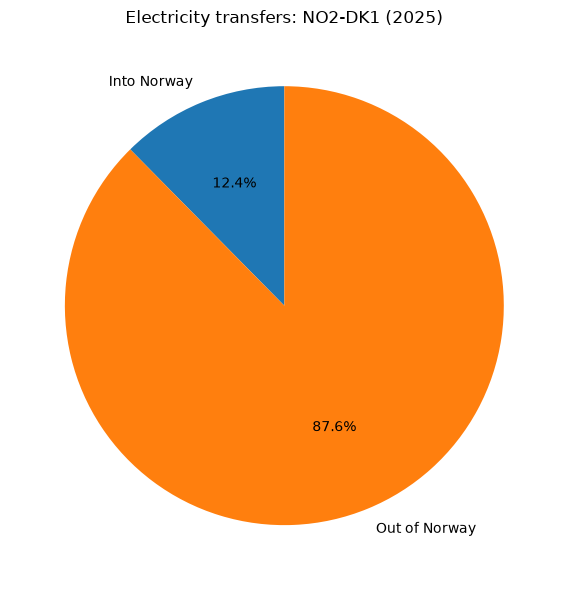

Annual transferred energy (GWh):


direction
Into Norway      1153.57
Out of Norway    8157.33
Name: energy_mwh, dtype: float64

In [23]:
# Select a connection and year for the annual comparison.
selected_connection = "NO2-DK1"
selected_year = 2025

# Filter the daily electricity transfers.
yearly_data = daily_flows_df[
    (daily_flows_df["connection"] == selected_connection) &
    (daily_flows_df["date_utc"].dt.year == selected_year)
]

# Calculate total energy transferred in each direction.
pie_data = (
    yearly_data.groupby("direction")["energy_mwh"]
    .sum()
    .reindex(["Into Norway", "Out of Norway"], fill_value=0)
)

# Create the annual import/export pie chart.
fig, ax = plt.subplots(figsize=(7, 6))

ax.pie(
    pie_data,
    labels=pie_data.index,
    autopct="%1.1f%%",
    startangle=90
)

ax.set_title(f"Electricity transfers: {selected_connection} ({selected_year})")

plt.tight_layout()
plt.show()

# Display the actual energy totals in GWh.
print("Annual transferred energy (GWh):")
display((pie_data / 1000).round(2))

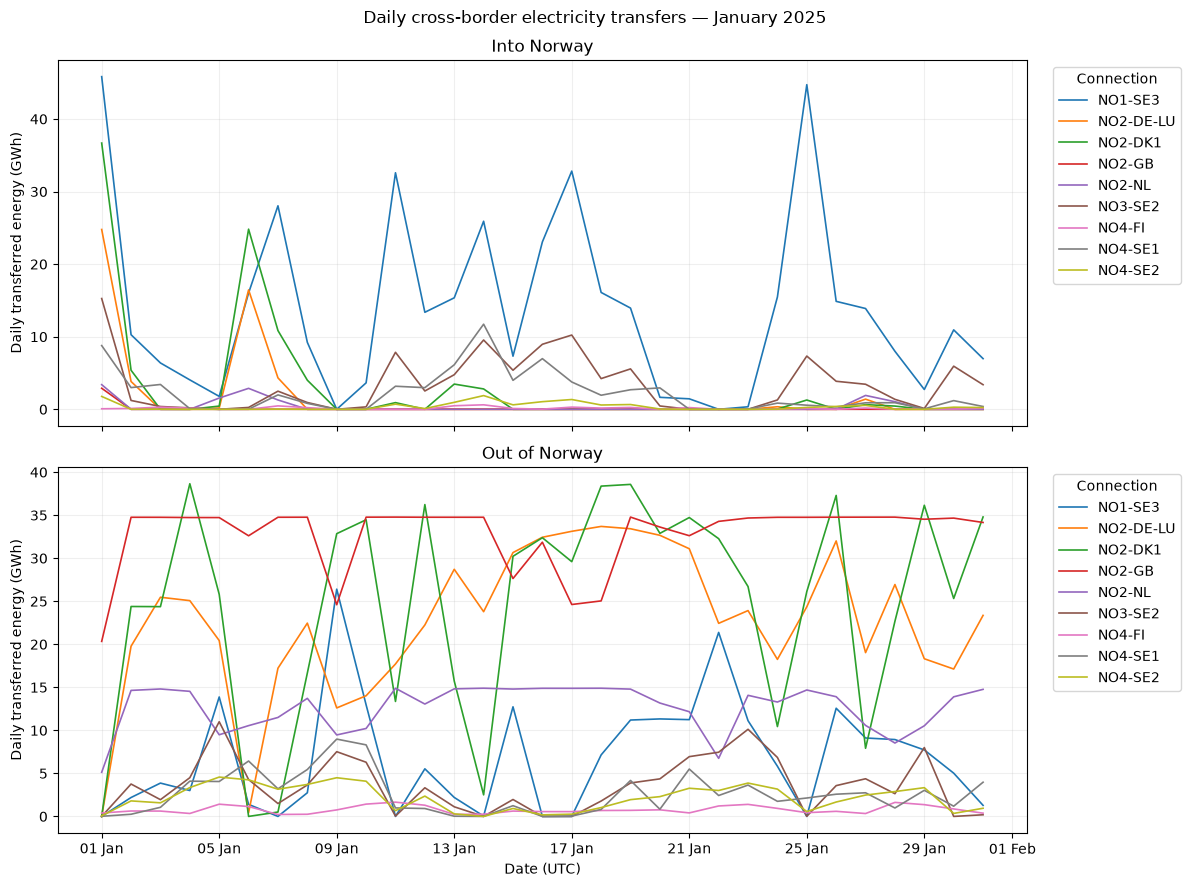

In [24]:
# Select the month and year for the line plot.
selected_year = 2025
selected_month = 1

monthly_data = daily_flows_df[
    (daily_flows_df["date_utc"].dt.year == selected_year) &
    (daily_flows_df["date_utc"].dt.month == selected_month)
].copy()

# Convert daily energy from MWh to GWh.
monthly_data["energy_gwh"] = monthly_data["energy_mwh"] / 1000

# Show imports and exports in separate panels.
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

for ax, direction in zip(axes, ["Into Norway", "Out of Norway"]):
    direction_data = monthly_data[monthly_data["direction"] == direction]

    for connection, group in direction_data.groupby("connection"):
        ax.plot(
            group["date_utc"],
            group["energy_gwh"],
            label=connection,
            linewidth=1.2
        )

    ax.set_title(direction)
    ax.set_ylabel("Daily transferred energy (GWh)")
    ax.legend(title="Connection", bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.grid(alpha=0.2)

month_label = pd.Timestamp(selected_year, selected_month, 1).strftime("%B %Y")
fig.suptitle(f"Daily cross-border electricity transfers — {month_label}")

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[-1].set_xlabel("Date (UTC)")

plt.tight_layout()
plt.show()


### Upload Spark data to MongoDB

In [25]:
# Prepare the daily electricity transfers for MongoDB.
collection = client["ind320_assignment2"][mongo_collection]

mongo_df = daily_flows_df.copy()
mongo_df["year"] = mongo_df["date_utc"].dt.year
mongo_df["month"] = mongo_df["date_utc"].dt.month
mongo_df["date_utc"] = mongo_df["date_utc"].dt.strftime("%Y-%m-%d")
mongo_df["data_source"] = "ENTSO-E API"

documents = mongo_df.to_dict("records")

# Enable only when MongoDB needs to be updated.
RUN_MONGODB_UPLOAD = False

if RUN_MONGODB_UPLOAD:
    # Ensure each connection, direction, and date is unique.
    collection.create_index(
        [("connection", 1), ("direction", 1), ("date_utc", 1)],
        unique=True
    )

    # Update existing records or insert new ones.
    operations = [
        ReplaceOne(
            {
                "connection": doc["connection"],
                "direction": doc["direction"],
                "date_utc": doc["date_utc"]
            },
            doc,
            upsert=True
        )
        for doc in documents
    ]

    # Upload in manageable batches.
    for i in range(0, len(operations), 500):
        collection.bulk_write(operations[i:i + 500], ordered=False)

    print("MongoDB upload completed.")
else:
    print("MongoDB upload skipped. Existing data preserved.")

print("Documents in MongoDB:", collection.count_documents({}))
display(mongo_df.head())

MongoDB upload skipped. Existing data preserved.
Documents in MongoDB: 13140


,connection,direction,date_utc,energy_mwh,year,month,data_source
0,NO1-SE3,Into Norway,2024-10-27,44152.755,2024,10,ENTSO-E API
1,NO1-SE3,Out of Norway,2024-10-27,0.000,2024,10,ENTSO-E API
2,NO2-DE-LU,Into Norway,2024-10-27,0.000,2024,10,ENTSO-E API
3,NO2-DE-LU,Out of Norway,2024-10-27,24927.040,2024,10,ENTSO-E API
4,NO2-DK1,Into Norway,2024-10-27,0.000,2024,10,ENTSO-E API


## Work log assignment 2

For this assignment, I took my previous project further by swapping the CSV files for live APIs and adding Cassandra, Spark, and MongoDB Atlas. The goal was to collect electricity and reservoir data, process it, and feed the results into my Streamlit app.

Getting the environment running on Windows (Docker, Cassandra, Java, and PySpark) was easily the hardest part. The Python environment, Spark, and the Cassandra connector kept running into compatibility problems. I eventually got everything working with PySpark 3.5.9, confirmed that Spark could talk to Cassandra, and tested the connection to MongoDB Atlas as well.

For the reservoir statistics, I pulled data straight from the NVE API instead of reading the old CSV. I turned the response into a Pandas DataFrame, identified the Norwegian geographical areas, and rebuilt the five individual visualizations and the combined normalized plot from Assignment 1.

The ENTSO-E part took more effort. My API token wasn't ready before the original deadline, so I started with clearly labeled demonstration data. Once I got access, I replaced it with real cross-border electricity-transfer measurements: two years of data, nine international connections, both directions. I parsed the XML responses, converted power in MW to energy in MWh, and used Spark to store everything in Cassandra.

While validating the data, I found that my timezone handling was producing wrong timestamps and dropping records around daylight-saving changes. I fixed the parser so it keeps UTC timestamps and fetched everything again. The final dataset had 492,913 measurements, and validation showed complete daily coverage for all 13,140 connection-direction observations.

From there, I used Spark to aggregate the measurements into daily electricity transfers and built an annual pie chart and monthly line plots. I uploaded the processed data to MongoDB Atlas, so the Streamlit app can use it without needing a local Spark or Cassandra setup.

Last, I cleaned up the notebook by removing temporary tests, demo data, and duplicate code. I learned a lot from this assignment about working with APIs, databases, data processing, and debugging. The peer-review feedback was also very useful, since it pointed out ways to improve the app's security (accidentally put the wrong path in .gitignore, so my old MongoDB token was leaked to github, though this is now fixed), documentation, and usability.

## AI Usage

I used ChatGPT to help with fixing code, debugging, and help understanding the API syntax and structure. It was especially useful when troubleshooting compatibility issues between Python, Spark, and Cassandra, as well as understanding the responses from the NVE and ENTSO-E APIs.

ChatGPT also helped me make tests the ENTSO-E data, and identifying a timezone problem that affected the Cassandra records. I also used it to help simplify code as my initial attemps were very messy, and improve some of my documentation.

I also gave suggested code and asked it to review and give suggested changes for better readability. 